# PIMC - Proton in a double well potential

In [1]:
import numpy as np
import scipy.constants as const
from dataclasses import dataclass

@dataclass
class SimulationParams:
    P: int
    N_sweep: int
    N: int
    C: float
    a: float
    m: float
    V0: float
    T: float
    omega_P: float
    dx: float

# Functions
def random_displacement(dx: float) -> float:
    """
    dx: Maximum displacement
    Generate a random displacement following dx*(eta-0.5), where eta is a uniform random number in [0, 1].
    """
    eta = np.random.uniform(0, 1)
    return dx * (2 * eta - 1)

def V(x: float, a: float, V0: float) -> float:
    """
    x: Position
    a: Potential length parameter
    V0: Potential energy parameter
    Potential energy function.
    """
    return V0 * ((x / a)**2 - 1)**2

def Delta_U(state: np.ndarray, bead_index: int, displacement: float, params: SimulationParams) -> float:
    """
    state: Current state of the system (positions of beads)
    bead_index: Index of the bead to be displaced
    displacement: Amount of displacement for the bead
    params: Simulation parameters
    Calculate the change in potential energy for a given bead index and displacement.
    """
    # Compute the diff in potential energy
    V_diff = (1/params.P) * (V(state[bead_index] + displacement, params.a, params.V0) - V(state[bead_index], params.a, params.V0))

    # Compute the diff in spring energy
    xj_old = state[bead_index]
    xj_new = xj_old + displacement
    xjp = state[(bead_index + 1) % params.P]
    xjm = state[(bead_index - 1) % params.P]
    spring_diff = 0.5 * params.m * params.omega_P**2 * ((xjp - xj_new)**2 + (xj_new - xjm)**2 - (xjp - xj_old)**2 - (xj_old - xjm)**2)
    return V_diff + spring_diff

def metropolis_acceptance(delta_U: float, params: SimulationParams) -> bool:
    """
    delta_U: Change in energy
    params: Simulation parameters
    Metropolis acceptance criterion.
    """
    if delta_U < 0:
        return True
    else:
        acceptance_prob = np.exp(-delta_U / (const.k * params.T))
        return np.random.uniform(0, 1) <= acceptance_prob

def algo_step(
        M_conf: np.ndarray, 
        success_list: np.ndarray, 
        sum_x: np.ndarray,
        sum_V: np.ndarray,
        i: int, 
        params: SimulationParams,
        ) -> None:
    """
    M_conf: Configuration state of beads
    success_list: List to store success rates
    sum_x: List to store sum of beads positions
    sum_V: List to store sum of potential energies
    i: Current iteration index
    params: Simulation parameters
    Perform a single step of the Metropolis algorithm.
    """
    # Randomly select a bead index
    bead_index = np.random.randint(0, params.P)

    # Generate a random displacement
    displacement = random_displacement(params.dx)

    # Calculate the change in potential energy
    delta_U = Delta_U(M_conf, bead_index, displacement, params)

    # Decide whether to accept the move
    if metropolis_acceptance(delta_U, params):
        x_old = M_conf[bead_index]
        M_conf[bead_index] += displacement
        success_list[i] = 1  # Move accepted
        if i != 0:
            sum_x[i] = sum_x[i-1] + M_conf[bead_index] - x_old  # Update the sum of beads positions
            sum_V[i] = sum_V[i-1] + V(M_conf[bead_index], params.a, params.V0) - V(x_old, params.a, params.V0)  # Update the sum of potential energies
            return
    else:
        success_list[i] = 0  # Move rejected
        if i != 0:
            sum_x[i] = sum_x[i-1]  # Store the sum of beads positions
            sum_V[i] = sum_V[i-1]  # Store the sum of potential energies
            return
    sum_x[i] = np.sum(M_conf)  # Store the sum of beads positions
    sum_V[i] = np.sum([V(x, params.a, params.V0) for x in M_conf])  # Store the sum of potential energies
    return


def run_simulation(N_sweep: int = 1000, P: int = 50, C: float = 0.3, a_corr: float = 1.0):
    """
    N_sweep: Number of sweeps
    P: Number of beads
    C: Unit reduction factor
    a_corr: Correction factor for tuning dx
    Run the Metropolis algorithm for N iterations.
    """

    # Constants
    a = 0.04e-9 # Potential lenght parameter
    m = const.m_p # proton mass
    V0 = const.hbar**2 / (2 * m * a**2 * C) # Potential energy parameter
    T = 0.4 * V0 / const.k # Simulation temperature
    omega_P = np.sqrt(P) * const.k * T / const.hbar # Quantum spring frequency
    P_ref = 50 # Reference number of beads for dx calculation
    dx_ref = 0.4 * a # Reference spatial step size
    dx = dx_ref * np.sqrt(P_ref / P) * a_corr # Adjusted spatial step size to maintain a similar acceptance rate (45%)
    N = N_sweep * P # Total number of iterations
    params = SimulationParams(
        P=P,
        N_sweep=N_sweep,
        N=N, 
        C=C, 
        a=a, 
        m=m, 
        V0=V0, 
        T=T, 
        omega_P=omega_P, 
        dx=dx,
        )

    # Initialization
    M_conf = a*np.ones(params.P) # Configuration state of beads
    success_list = np.zeros(N, dtype=int) # List to store success rates
    sum_x = np.zeros(N) # List to store sum of beads positions
    sum_V = np.zeros(N) # List to store sum of potential energies

    for i in range(int(N)):
        algo_step(
            M_conf, 
            success_list, 
            sum_x,
            sum_V,
            i, 
            params,
            )

    return (M_conf, success_list, sum_x / params.P, sum_V / params.P, params)

# Run simulation

In [2]:
M_conf, success_list, centroid_positions, mean_energies, params = run_simulation(10000, 1, C=0.3, a_corr=0.3)

# Result analysis

Success rate: 47.16%
Mean energy: 9.2414e-03 eV
Variance of energy: 1.3335e-04 eV^2
Mean centroid position: 4.9086e-12 m
Mean controid position (reduced units): 1.2272e-01 a
Variance of centroid position: 1.3942e-21 m^2


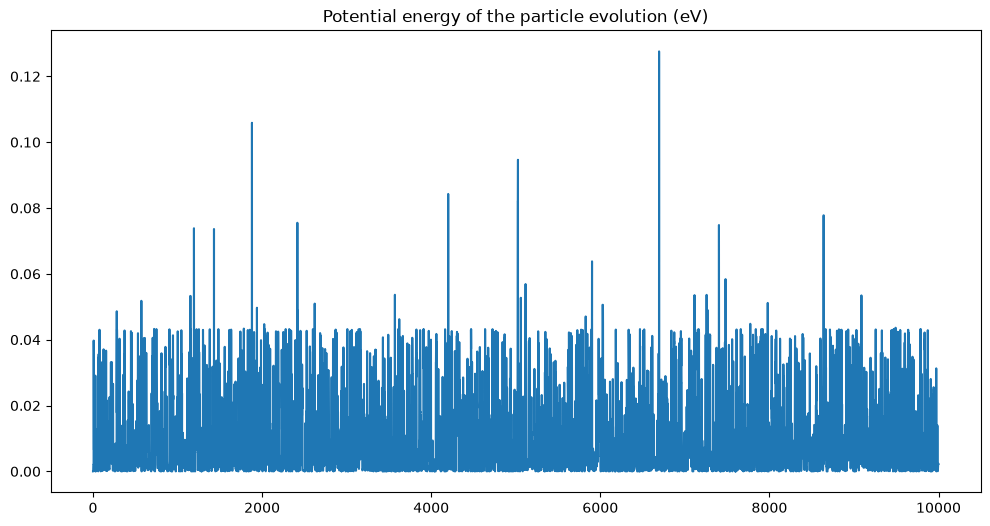

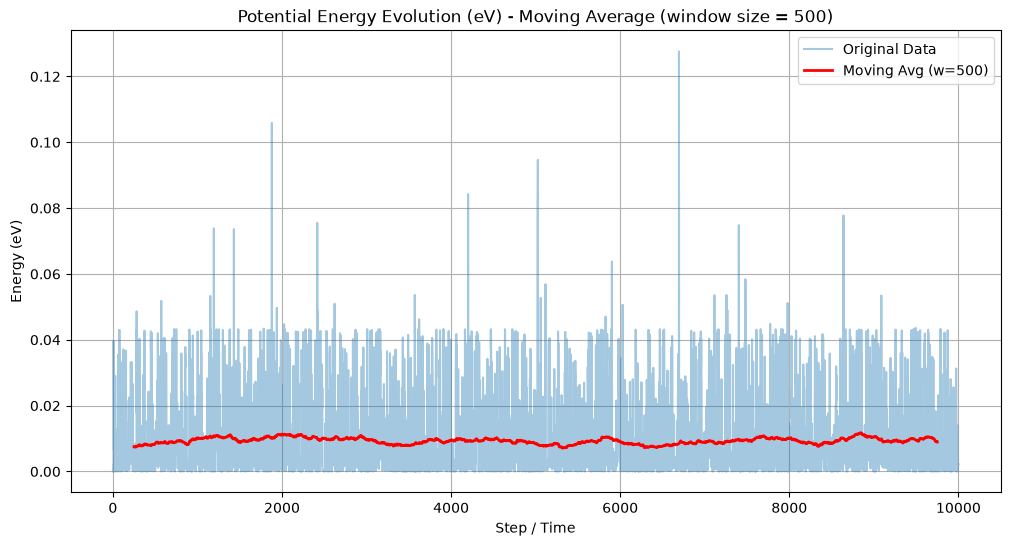

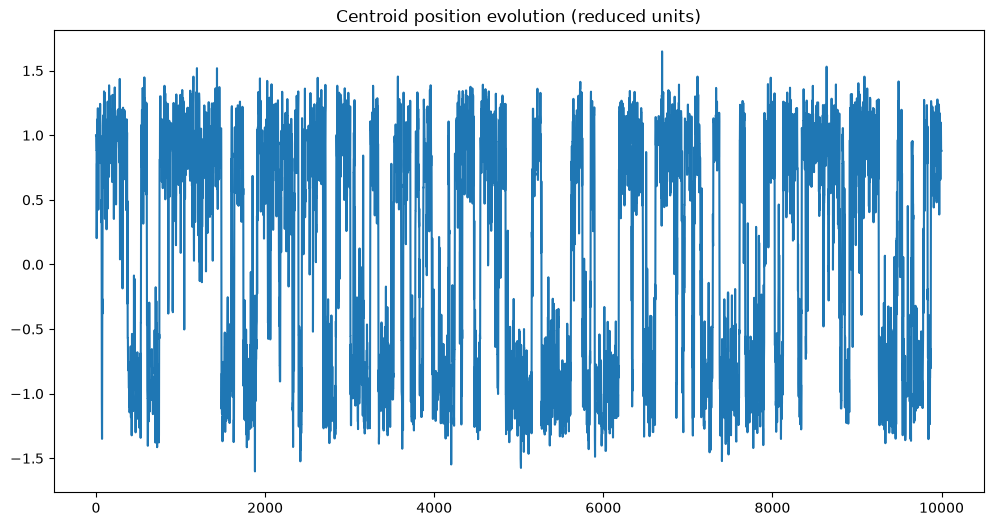

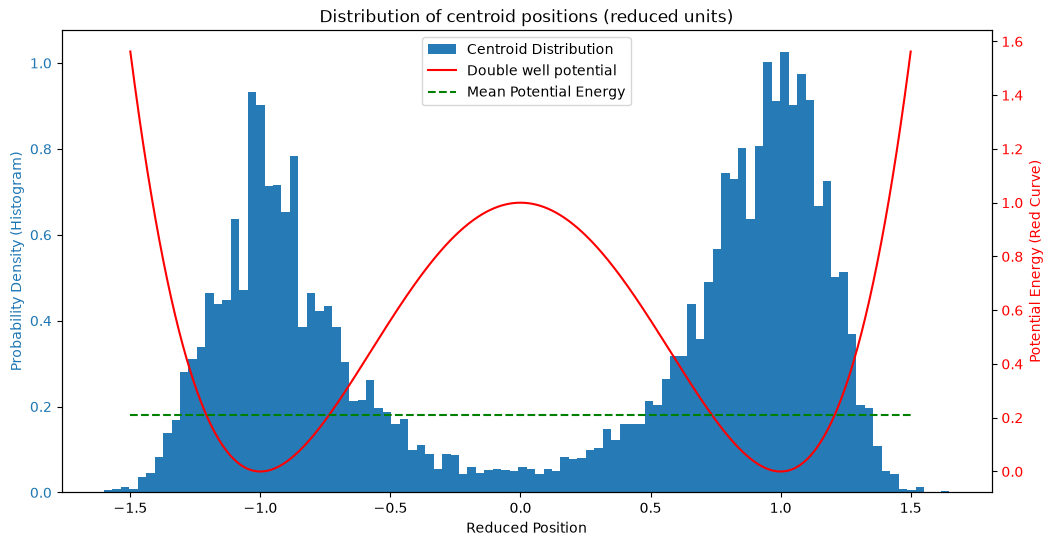

In [3]:
# Success rate calculation (should be between 40% and 50%, if not change dx)
success_rate = np.mean(success_list) * 100
print(f"Success rate: {success_rate:.2f}%")
P = params.P
a = params.a
V0 = params.V0
N = params.N

# Mean energy calculation
print(f"Mean energy: {np.mean(mean_energies) / const.e:.4e} eV")
print(f"Variance of energy: {np.var(mean_energies) / (const.e**2):.4e} eV^2")
mean_energy_prod = np.mean(mean_energies[int(np.ceil(N/2)):])  # Mean energy after equilibration (discard first half of the simulation)

# Centroid distribution calculation

print(f"Mean centroid position: {np.mean(centroid_positions):.4e} m")
print(f"Mean controid position (reduced units): {np.mean(centroid_positions) / a:.4e} a")
print(f"Variance of centroid position: {np.var(centroid_positions):.4e} m^2")

# Plots
import matplotlib.pyplot as plt

## Plot energy evolution
plt.figure(figsize=(12, 6))
plt.plot(mean_energies / const.e)
plt.title('Potential energy of the particle evolution (eV)')

## Plot energy evolution with moving average
window_size = int(N * 0.05)
energies_eV = mean_energies / const.e
kernel = np.ones(window_size) / window_size
moving_avg = np.convolve(energies_eV, kernel, mode='valid')
x_original = np.arange(N)  # Replace with actual time/step array if available
offset = (window_size - 1) / 2.0
x_moving_avg = x_original[:len(moving_avg)] + offset
plt.figure(figsize=(12, 6))
plt.plot(x_original, energies_eV, alpha=0.4, label='Original Data')
plt.plot(x_moving_avg, moving_avg, color='red', linewidth=2, label=f'Moving Avg (w={window_size})')
plt.title(f'Potential Energy Evolution (eV) - Moving Average (window size = {window_size})')
plt.xlabel('Step / Time')
plt.ylabel('Energy (eV)')
plt.legend()
plt.grid(True)
plt.show()

## Plot centroid (reduced positions)
plt.figure(figsize=(12, 6))
plt.plot(centroid_positions/a)
plt.title('Centroid position evolution (reduced units)')

# Plot distribution of centroid positions (reduced position)
fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.hist(centroid_positions / a, bins=100, density=True, alpha=0.97, color='tab:blue', label='Centroid Distribution')
ax1.set_xlabel('Reduced Position')
ax1.set_ylabel('Probability Density (Histogram)', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
x = np.linspace(-1.5, 1.5, 1000)
y = (x**2 - 1)**2

ax2.plot(x, y, color='red', label='Double well potential')
ax2.plot(x, mean_energy_prod / V0 * np.ones_like(x), color='green', linestyle='--', label='Mean Potential Energy')
ax2.set_ylabel('Potential Energy (Red Curve)', color='red')
ax2.tick_params(axis='y', labelcolor='red')

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')

plt.title('Distribution of centroid positions (reduced units)')
plt.show()




# Run simulation with P increasing

Success rate for P=1: 16.50%
Mean energy for P=1: 8.8675e-03 eV
Mean centroid position for P=1: 1.4149e-01 a
----------------------------------------
Success rate for P=56: 46.42%
Mean energy for P=56: 1.5354e-02 eV
Mean centroid position for P=56: 9.5421e-01 a
----------------------------------------
Success rate for P=111: 46.35%
Mean energy for P=111: 8.7616e-03 eV
Mean centroid position for P=111: 8.6493e-01 a
----------------------------------------
Success rate for P=167: 46.33%
Mean energy for P=167: 1.3641e-02 eV
Mean centroid position for P=167: 1.0607e+00 a
----------------------------------------
Success rate for P=222: 46.28%
Mean energy for P=222: 6.0150e-03 eV
Mean centroid position for P=222: 9.6069e-01 a
----------------------------------------
Success rate for P=278: 46.07%
Mean energy for P=278: 5.0690e-03 eV
Mean centroid position for P=278: 9.9624e-01 a
----------------------------------------
Success rate for P=333: 46.37%
Mean energy for P=333: 4.2553e-03 eV
Mean 

Text(0, 0.5, 'Mean energy (eV)')

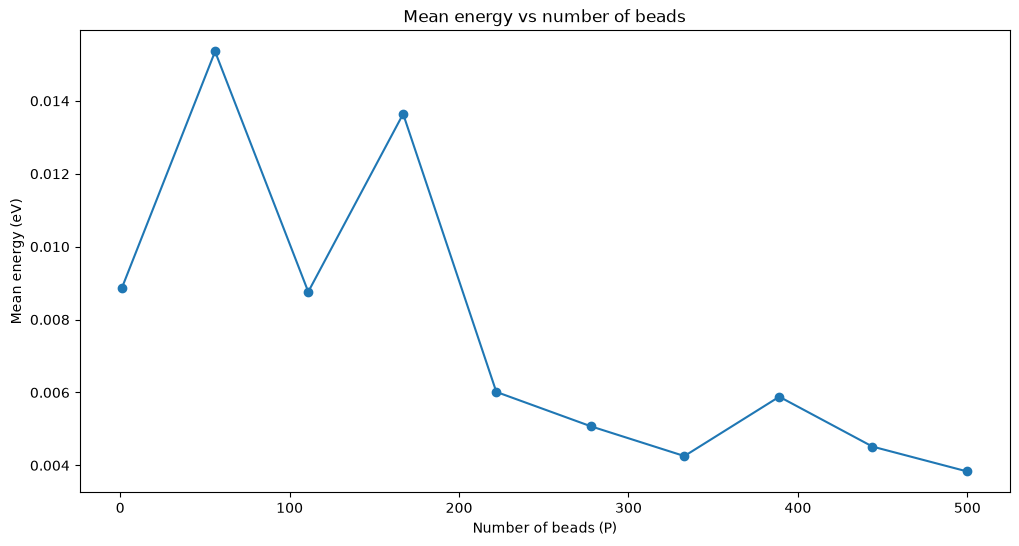

In [4]:
P_list = np.linspace(1, 500, 10, dtype=int)  # List of number of beads to test
energy_list = []
for P in P_list:
    M_conf, success_list, centroid_positions, mean_energies, params = run_simulation(1000, P)
    success_rate = np.mean(success_list) * 100
    print(f"Success rate for P={P}: {success_rate:.2f}%")
    print(f"Mean energy for P={P}: {np.mean(mean_energies[3*P:]) / const.e:.4e} eV")
    print(f"Mean centroid position for P={P}: {np.mean(centroid_positions) / params.a:.4e} a")
    print("-" * 40)
    energy_list.append(np.mean(mean_energies[3*P:]))  # Mean energy after equilibration (to be fined-tuned)


# Plot mean energy vs number of beads
plt.figure(figsize=(12, 6))
plt.plot(P_list, np.array(energy_list) / const.e, marker='o')
plt.title('Mean energy vs number of beads')
plt.xlabel('Number of beads (P)')
plt.ylabel('Mean energy (eV)')